# Assignment: N-Queens with First Queen Placed (Backtracking)

In [5]:
def is_safe(board, row, col, n):
    # check column above
    for i in range(row):
        if board[i][col] == 'Q':
            return False

    # check upper-left
    i, j = row - 1, col - 1
    while i >= 0 and j >= 0:
        if board[i][j] == 'Q':
            return False
        i -= 1
        j -= 1

    # check upper-right
    i, j = row - 1, col + 1
    while i >= 0 and j < n:
        if board[i][j] == 'Q':
            return False
        i -= 1
        j += 1

    return True


def n_queens(n, fixed_row, fixed_col, show=True):
    board = [['.'] * n for i in range(n)]
    board[fixed_row][fixed_col] = 'Q'
    count = 0

    def solve(row):
        nonlocal count

        if row == n:
            count += 1
            if show:
                for i in range(n):
                    print(' '.join(board[i]))
                print()
            return

        if row == fixed_row:
            solve(row + 1)
            return

        for col in range(n):
            if is_safe(board, row, col, n):
                board[row][col] = 'Q'
                solve(row + 1)
                board[row][col] = '.'

    solve(0)
    return count


n = 4
fixed_row = 0
fixed_col = 1

print("N =", n)
print("First queen at", fixed_row, fixed_col)
print()
ans = n_queens(n, fixed_row, fixed_col)
print("Total solutions:", ans)
print("Time: O(N!)")
print("Space: O(N)")

N = 4
First queen at 0 1

. Q . .
. . . Q
Q . . .
. . Q .

Total solutions: 1
Time: O(N!)
Space: O(N)


# Analysis: Time and Memory Comparison

N	Time (s)		Peak Memory (KB)
4	0.00000720		1.172
5	0.00002120		1.953
6	0.00006450		2.164
7	0.00024140		2.391
8	0.00096540		2.633
9	0.00570120		2.984
10	0.02384730		3.258
11	0.11521900		3.547


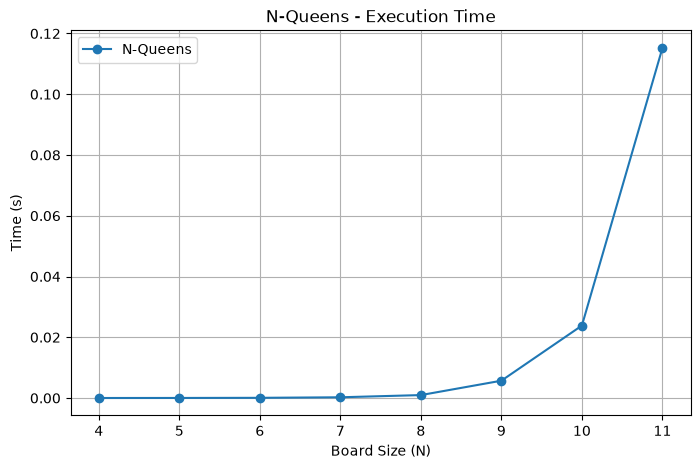

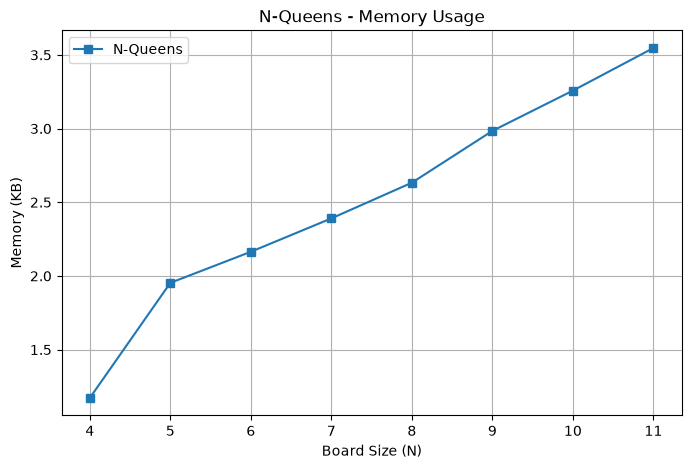

In [2]:
import matplotlib.pyplot as plt
from time import perf_counter
import tracemalloc
import statistics


def measure_time(function, *args, repeats=5):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        function(*args)
        times.append(perf_counter() - start)
    return statistics.median(times)


def measure_memory(function, *args, repeats=3):
    memory_values = []
    for _ in range(repeats):
        tracemalloc.start()
        function(*args)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        memory_values.append(peak / 1024)
    return statistics.median(memory_values)


sizes = list(range(4, 12))
execution_times = []
peak_memory = []

for size in sizes:
    execution_times.append(measure_time(n_queens, size, 0, 1, False))
    peak_memory.append(measure_memory(n_queens, size, 0, 1, False))


print("N\tTime (s)\t\tPeak Memory (KB)")
for size, t, m in zip(sizes, execution_times, peak_memory):
    print(f"{size}\t{t:.8f}\t\t{m:.3f}")


plt.figure(figsize=(8, 5))
plt.plot(sizes, execution_times, marker='o', label="N-Queens")
plt.xlabel("Board Size (N)")
plt.ylabel("Time (s)")
plt.title("N-Queens - Execution Time")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(sizes, peak_memory, marker='s', label="N-Queens")
plt.xlabel("Board Size (N)")
plt.ylabel("Memory (KB)")
plt.title("N-Queens - Memory Usage")
plt.legend()
plt.grid(True)
plt.show()